# Week 1 — CartPole Policy Experiment

## 연구 질문
CartPole에서 상태 정보를 활용하는 방식에 따라 제어 성능이 어떻게 달라질까?

## 가설
1. 무작위 행동보다 상태를 고려한 정책이 좋은 성능을 보일 것이다.
2. 막대의 각도뿐 아니라 각속도를 고려하면 성능이 달라질 것이다.
3. 선형 정책의 가중치를 변경하면 평균 Reward가 변화할 것이다.

## 실험 조건
- Environment: CartPole-v1
- Episodes: 정책별 30회
- Seed: 42~71
- Metric: Mean Reward, Standard Deviation, Success Rate

In [1]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path.cwd()
# 노트북을 week01 폴더에서 실행할 때를 기준으로 함

env = gym.make("CartPole-v1")
state, info = env.reset(seed=42)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)
print("State shape:", state.shape)

env.close()


Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
State shape: (4,)


In [2]:

def random_policy(state, env):
    return env.action_space.sample()


def angle_policy(state, env):
    return 1 if state[2] > 0 else 0


def angle_velocity_policy(state, env):
    score = state[2] + 0.5 * state[3]
    return 1 if score > 0 else 0


policies = {
    "Random": random_policy,
    "Angle": angle_policy,
    "Angle + Velocity": angle_velocity_policy,
}


In [3]:

def run_episode(env, policy, seed):
    state, info = env.reset(seed=seed)
    env.action_space.seed(seed)

    total_reward = 0.0
    steps = 0

    while True:
        action = policy(state, env)

        next_state, reward, terminated, truncated, info = env.step(action)

        total_reward += reward
        steps += 1
        state = next_state

        if terminated or truncated:
            return total_reward, steps, terminated, truncated


In [5]:

results = {}
summary = {}

for policy_name, policy_fn in policies.items():
    env = gym.make("CartPole-v1")
    rewards = []
    successes = 0

    for episode in range(30):
        reward, steps, terminated, truncated = run_episode(
            env, policy_fn, seed=42 + episode
        )

        rewards.append(reward)

        if reward >= 500:
            successes += 1

    env.close()

    results[policy_name] = rewards

    summary[policy_name] = {
        "mean": np.mean(rewards),
        "std": np.std(rewards),
        "success_rate": successes / 30,
    }

    print(
        f"{policy_name:20s} | "
        f"Mean={summary[policy_name]['mean']:.2f} | "
        f"Std={summary[policy_name]['std']:.2f} | "
        f"500-step rate={summary[policy_name]['success_rate']:.1%}"
    )


Random               | Mean=25.73 | Std=17.96 | 500-step rate=0.0%
Angle                | Mean=43.53 | Std=8.38 | 500-step rate=0.0%
Angle + Velocity     | Mean=500.00 | Std=0.00 | 500-step rate=100.0%


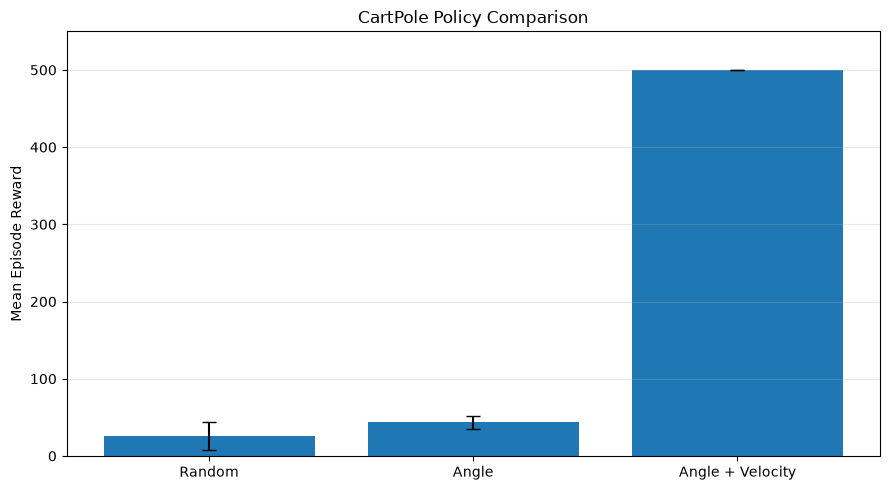

In [6]:

names = list(summary.keys())
means = [summary[name]["mean"] for name in names]
stds = [summary[name]["std"] for name in names]

plt.figure(figsize=(9, 5))
plt.bar(names, means, yerr=stds, capsize=5)

plt.ylabel("Mean Episode Reward")
plt.title("CartPole Policy Comparison")
plt.ylim(0, 550)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "reward_comparison.png", dpi=150)
plt.show()


k=0.0, Mean Reward=43.53
k=0.1, Mean Reward=500.00
k=0.3, Mean Reward=500.00
k=0.5, Mean Reward=500.00
k=1.0, Mean Reward=485.97
k=2.0, Mean Reward=420.90


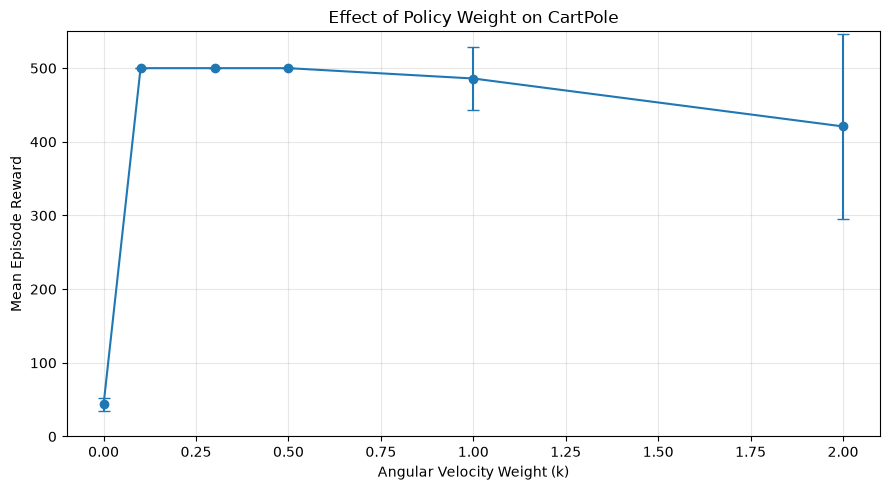

In [7]:

def make_linear_policy(k):
    weights = np.array([0, 0, 1, k])

    def policy(state, env):
        score = np.dot(weights, state)
        return 1 if score > 0 else 0

    return policy


k_values = [0.0, 0.1, 0.3, 0.5, 1.0, 2.0]
weight_results = {}

env = gym.make("CartPole-v1")

for k in k_values:
    policy = make_linear_policy(k)
    rewards = []

    for episode in range(30):
        reward, steps, terminated, truncated = run_episode(
            env, policy, seed=42 + episode
        )
        rewards.append(reward)

    weight_results[k] = rewards
    print(f"k={k:.1f}, Mean Reward={np.mean(rewards):.2f}")

env.close()

weight_means = [np.mean(weight_results[k]) for k in k_values]
weight_stds = [np.std(weight_results[k]) for k in k_values]

plt.figure(figsize=(9, 5))
plt.errorbar(
    k_values, weight_means,
    yerr=weight_stds,
    fmt="o-", capsize=4
)

plt.xlabel("Angular Velocity Weight (k)")
plt.ylabel("Mean Episode Reward")
plt.title("Effect of Policy Weight on CartPole")
plt.ylim(0, 550)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "weight_comparison.png", dpi=150)
plt.show()


## 실험 결론

### 1. 정책 비교
- Random 평균 Reward: 25.73
- Angle 평균 Reward: 43.53
- Angle + Velocity 평균 Reward: 500.00
- 평균 Reward가 가장 높았던 정책: Angle + Velocity
- 해당 정책이 좋은 성능을 보인 이유에 대한 가설: Velocity에 따라 막대의 기울어지는 정도도 반영

### 2. 가중치 실험
- 실험한 가중치: 0.0, 0.1, 0.3, 0.5, 1.0, 2.0
- 가장 높은 평균 Reward를 보인 가중치: 0.1, 0.3, 0.5
- 가중치를 증가시킬 때 관찰한 현상: 점점 reward 평균이 떨어짐

### 3. 선형대수와의 연결
상태 벡터와 가중치 벡터의 내적을 이용해 행동 결정 점수를 계산했다.

\[
z=w^Ts
\]

가중치가 달라지면 같은 상태에서도 다른 행동을 선택할 수 있다.

### 4. 한계
- 정책의 가중치를 사람이 직접 설정했다.
- 이번 실험은 강화학습 알고리즘을 사용하지 않았다.
- 30개 초기 상태에서의 결과이므로 모든 상황에서의 성능을 보장하지 않는다.

### 5. 다음 연구 질문
보상을 활용해 좋은 정책의 가중치를 자동으로 학습하려면 어떻게 해야 할까?